# Customer Churn Prediction – Grupp 8

**Kurs:** Statistisk programmering och maskininlärning  
**Utbildning:** BI-analytiker, Nackademin  
**Gruppmedlemmar:** David, Adam, Andy och Daro

## Introduktion och projektbeskrivning

### Bakgrund

Kundbortfall, även kallat Customer Churn, innebär att kunder avslutar sina abonnemang eller slutar använda ett företags tjänster.

För företag med abonnemangsbaserade affärsmodeller är det viktigt att förstå vilka faktorer som har samband med kundbortfall.

Genom statistisk analys och maskininlärning kan företag undersöka historiska kundmönster och utveckla modeller som identifierar kunder med förhöjd risk för kundbortfall.

### Syfte och frågeställning

Syftet med vårt projekt är att undersöka om maskininlärning kan användas för att förutsäga vilka kunder som riskerar att lämna ett företag.

**Vår huvudsakliga frågeställning är:**

Kan vi med hjälp av historisk kunddata och maskininlärning identifiera kunder med risk för kundbortfall?

Vi vill även undersöka vilka kundegenskaper som har samband med kundbortfall och jämföra två olika maskininlärningsmodeller.

### Dataset

Vi använder IBM Telco Customer Churn Dataset, som innehåller 7 043 kundposter och 21 kolumner.

Datasetet innehåller bland annat information om:

- Kundernas avtalstyper.
- Månadskostnader och totala kostnader.
- Hur länge kunderna har varit hos företaget.
- Vilka tjänster kunderna använder.
- Om kunderna har lämnat företaget eller inte.

**Datakälla:** [IBM Telco Customer Churn Dataset](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv)

### Metod

Projektet genomförs med Python i Google Colab.

Vi använder pandas för datahantering, Matplotlib för visualiseringar, SciPy för statistiska tester och scikit-learn för maskininlärning.

Vi undersöker datasetet genom Exploratory Data Analysis (EDA), datarensning och statistiska tester.

Därefter tränar och utvärderar vi två maskininlärningsmodeller:

1. Logistic Regression
2. Random Forest

Modellerna jämförs med hjälp av Accuracy, Precision, Recall och F1-score.

Målet är att identifiera en lämplig modell för att förutsäga kundbortfall och diskutera hur resultaten skulle kunna användas inom Business Intelligence.

In [1]:

import pandas as pd

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Antal rader och kolumner:", df.shape)

display(df.head())


Antal rader och kolumner: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

# Undersök datasetets struktur
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:

# Kontrollera saknade värden
print("Saknade värden per kolumn:")
print(df.isnull().sum())

# Kontrollera tomma värden i TotalCharges
print("\nTomma värden i TotalCharges:")
print((df["TotalCharges"].str.strip() == "").sum())


Saknade värden per kolumn:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Tomma värden i TotalCharges:
11


In [4]:

# Hitta kunder med tomma TotalCharges
missing_charges = df[
    df["TotalCharges"].str.strip() == ""
]

# Visa relevanta kolumner för dessa kunder
display(missing_charges[
    ["customerID", "tenure", "MonthlyCharges",
     "TotalCharges", "Churn"]
])


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [5]:

# Skapa en kopia av originaldatan
df_clean = df.copy()

# Omvandla TotalCharges till numeriska värden
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

# Kontrollera att saknade värden gäller nya kunder
missing = df_clean["TotalCharges"].isna()

assert (df_clean.loc[missing, "tenure"] == 0).all()

# Ersätt saknade värden med 0
df_clean.loc[missing, "TotalCharges"] = 0

# Kontrollera resultatet
print("Antal kunder:", len(df_clean))
print("Saknade TotalCharges:", df_clean["TotalCharges"].isna().sum())
print("Datatyp:", df_clean["TotalCharges"].dtype)


Antal kunder: 7043
Saknade TotalCharges: 0
Datatyp: float64


## Datarensning (Data Cleaning)

Vid undersökningen av datasetet identifierades 11 tomma värden i kolumnen `TotalCharges`. Dessa värden var lagrade som tomma textsträngar och identifierades därför inte som vanliga saknade värden.

Vi undersökte dessa kunder och konstaterade att samtliga hade `tenure = 0`, vilket innebär noll registrerade månader som kunder.

Vi valde därför att ersätta de saknade värdena med 0, utifrån antagandet att kunderna ännu inte hade några registrerade totala betalningar. Detta är ett rimligt antagande, men kan inte bekräftas utan ytterligare betalningsinformation.

Kolumnen `TotalCharges` omvandlades även från text till numerisk datatyp (`float64`).

Efter datarensningen innehåller datasetet fortfarande 7 043 kunder och inga saknade värden i `TotalCharges`.

In [6]:

# Undersök fördelningen av kundbortfall
churn_counts = df_clean["Churn"].value_counts()

print("Antal kunder per kategori:")
print(churn_counts)

print("\nAndel kunder i procent:")
print(df_clean["Churn"].value_counts(normalize=True) * 100)


Antal kunder per kategori:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Andel kunder i procent:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


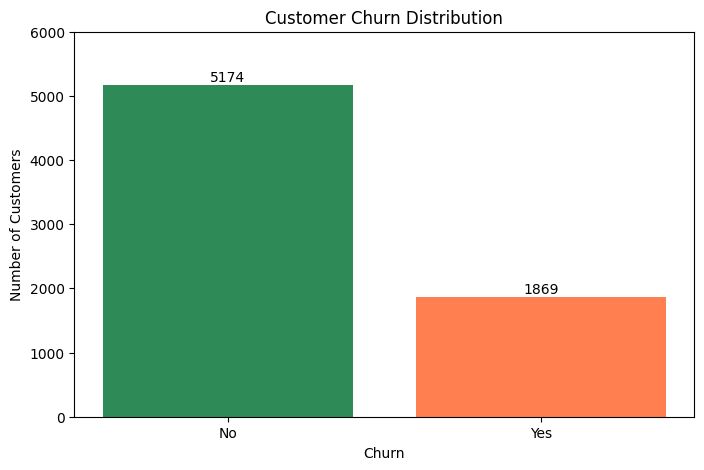

In [7]:

import matplotlib.pyplot as plt

# Antal kunder som stannat respektive lämnat
churn_counts = df_clean["Churn"].value_counts()

# Skapa stapeldiagram
plt.figure(figsize=(8, 5))

bars = plt.bar(
    churn_counts.index,
    churn_counts.values,
    color=["seagreen", "coral"]
)

# Lägg till antal ovanför staplarna
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        str(int(bar.get_height())),
        ha="center"
    )

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.ylim(0, 6000)
plt.show()


## Analys av kundbortfall (Customer Churn)

För att undersöka fördelningen av kundbortfall analyserade vi kolumnen `Churn` och visualiserade resultatet med ett stapeldiagram.

Analysen visar att 5 174 kunder (73,46 %) har stannat kvar hos företaget, medan 1 869 kunder (26,54 %) har avslutat sina abonnemang.

Det innebär att ungefär var fjärde kund i datasetet har lämnat företaget.

Resultatet visar även att datasetet har en ojämn klassfördelning, eftersom betydligt fler kunder tillhör kategorin `No` än `Yes`.

Detta är viktigt att ta hänsyn till vid maskininlärningen. En modell som alltid förutsäger `No` skulle uppnå cirka 73,46 % accuracy utan att korrekt identifiera någon kund som lämnar företaget.

Därför kommer vi även att använda utvärderingsmått som Precision, Recall och F1-score för att bedöma modellens förmåga att identifiera kundbortfall.

In [8]:

# Undersök kundbortfall baserat på avtalstyp

# Antal kunder per avtalstyp och Churn
contract_counts = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

print("Antal kunder per avtalstyp:")
display(contract_counts)

# Beräkna procentuell fördelning inom varje avtalstyp
contract_percent = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"],
    normalize="index"
) * 100

print("Kundbortfall i procent per avtalstyp:")
display(contract_percent.round(2))


Antal kunder per avtalstyp:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Kundbortfall i procent per avtalstyp:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


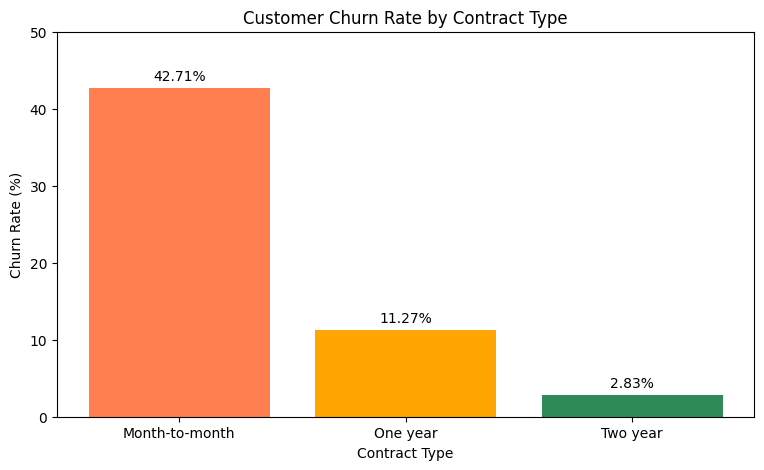

In [9]:

# Kundbortfall i procent per avtalstyp
contract_order = ["Month-to-month", "One year", "Two year"]

churn_by_contract = contract_percent.loc[
    contract_order, "Yes"
]

# Skapa stapeldiagram
plt.figure(figsize=(9, 5))

bars = plt.bar(
    churn_by_contract.index,
    churn_by_contract.values,
    color=["coral", "orange", "seagreen"]
)

# Visa procent ovanför staplarna
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.show()


## Analys av kundbortfall per avtalstyp (Contract Type)

För att undersöka sambandet mellan avtalstyp och kundbortfall analyserade vi kolumnerna `Contract` och `Churn`.

Vi beräknade andelen kunder som lämnat företaget inom varje avtalstyp och visualiserade resultaten med ett stapeldiagram.

Resultaten visar följande:

- **Månadsavtal (Month-to-month):** 42,71 % kundbortfall.
- **Ettårsavtal (One year):** 11,27 % kundbortfall.
- **Tvåårsavtal (Two year):** 2,83 % kundbortfall.

Analysen visar att kunder med månadsavtal har en betydligt högre andel kundbortfall jämfört med kunder som har längre avtal.

Kundbortfallet är ungefär 15 gånger så högt bland kunder med månadsavtal som bland kunder med tvåårsavtal.

Detta tyder på ett tydligt samband mellan avtalstyp och kundbortfall. Resultatet innebär dock inte att avtalstypen i sig orsakar kundbortfallet, eftersom även andra faktorer kan påverka kundernas beslut.

Avtalstyp kan därför vara en relevant variabel att inkludera i vår framtida maskininlärningsmodell.

In [10]:

# Analysera månadskostnader baserat på kundbortfall

monthly_analysis = df_clean.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median", "min", "max"]
)

# Avrunda resultatet till två decimaler
monthly_analysis = monthly_analysis.round(2)

print("Månadskostnader baserat på kundbortfall:")
display(monthly_analysis)


Månadskostnader baserat på kundbortfall:


,count,mean,median,min,max
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


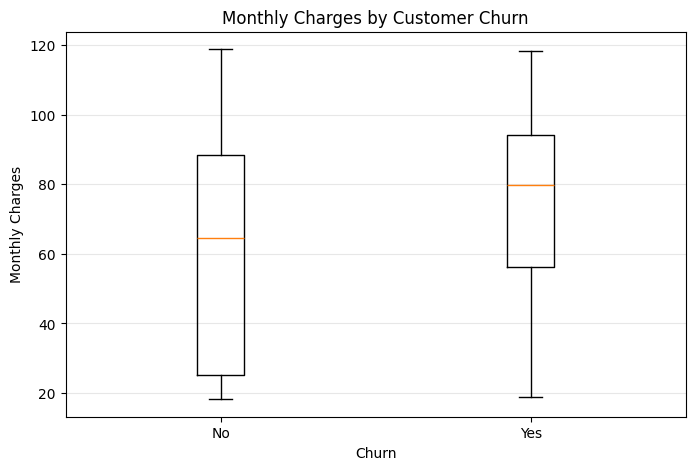

In [11]:

# Jämför månadskostnader mellan kunder som stannat och lämnat
plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df_clean[df_clean["Churn"] == "No"]["MonthlyCharges"],
        df_clean[df_clean["Churn"] == "Yes"]["MonthlyCharges"]
    ],
    tick_labels=["No", "Yes"]
)

plt.title("Monthly Charges by Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.grid(axis="y", alpha=0.3)
plt.show()


## Analys av månadskostnader (Monthly Charges)

För att undersöka sambandet mellan månadskostnader och kundbortfall analyserade vi variabeln `MonthlyCharges` för kunder som stannat respektive lämnat företaget.

Vi beräknade medelvärde, median, minimi- och maximivärde samt visualiserade fördelningen med hjälp av ett boxplot-diagram.

Analysen visar att kunder som lämnat företaget hade en genomsnittlig månadskostnad på 74,44, jämfört med 61,27 för kunder som stannat kvar.

Medianen var också högre bland kunder som lämnat (79,65) jämfört med kunder som stannat (64,43).

Resultaten visar ett samband mellan högre månadskostnader och kundbortfall. Samtidigt finns en betydande överlappning mellan grupperna, vilket innebär att månadskostnaden ensam inte kan avgöra om en kund kommer att lämna företaget.

Vi bedömer därför att `MonthlyCharges` kan vara en relevant variabel att inkludera i vår maskininlärningsmodell, tillsammans med andra kundegenskaper.

In [12]:

# Analysera kundernas tid hos företaget

tenure_analysis = df_clean.groupby("Churn")["tenure"].agg(
    ["count", "mean", "median", "min", "max"]
)

# Avrunda resultatet
tenure_analysis = tenure_analysis.round(2)

print("Kundernas tid hos företaget baserat på Churn:")
display(tenure_analysis)


Kundernas tid hos företaget baserat på Churn:


,count,mean,median,min,max
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


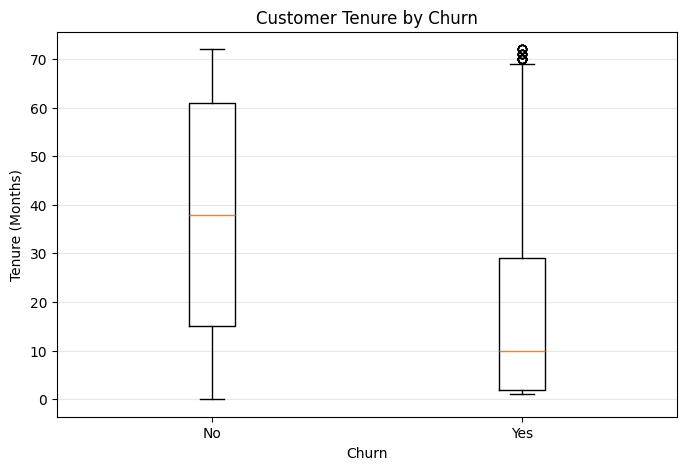

In [13]:

# Jämför kundernas tid hos företaget

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        df_clean[df_clean["Churn"] == "No"]["tenure"],
        df_clean[df_clean["Churn"] == "Yes"]["tenure"]
    ],
    tick_labels=["No", "Yes"]
)

plt.title("Customer Tenure by Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.grid(axis="y", alpha=0.3)

plt.show()


## Analys av kundtid (Tenure)

För att undersöka sambandet mellan kundernas tid hos företaget och kundbortfall analyserade vi variabeln `tenure`, som visar hur många månader en kund har varit hos företaget.

Vi beräknade medelvärde, median, minimi- och maximivärde för kunder som stannat respektive lämnat företaget. Resultaten visualiserades med ett boxplot-diagram.

Analysen visar att kunder som stannat kvar hade en genomsnittlig kundtid på 37,57 månader, medan kunder som lämnat hade en genomsnittlig kundtid på 17,98 månader.

Medianen var 38 månader för kunder som stannat och 10 månader för kunder som lämnat.

Diagrammet visar också att det finns kunder med lång kundhistorik som har lämnat företaget.

Resultaten tyder på ett samband mellan kortare kundtid och kundbortfall. Sambandet innebär dock inte att kort kundtid i sig orsakar kundbortfall.

Vi bedömer därför att `tenure` är en relevant variabel att inkludera i vår framtida maskininlärningsmodell.

In [14]:

from scipy.stats import chi2_contingency

# Skapa en korstabell
contingency_table = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

# Genomför Chi-Square Test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

# Visa resultatet
print("Chi-Square Test: Contract vs Churn")
print(f"Chi-Square Statistic: {chi2:.2f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of Freedom: {dof}")
print(f"Minimum Expected Frequency: {expected.min():.2f}")

# Tolka resultatet
if p_value < 0.05:
    print("Resultat: Statistiskt signifikant samband.")
else:
    print("Resultat: Inget statistiskt signifikant samband.")


Chi-Square Test: Contract vs Churn
Chi-Square Statistic: 1184.60
P-value: 0.000000
Degrees of Freedom: 2
Minimum Expected Frequency: 390.89
Resultat: Statistiskt signifikant samband.


## Statistiskt test – Chi-Square Test (Contract vs Churn)

För att undersöka om det finns ett statistiskt signifikant samband mellan avtalstyp (`Contract`) och kundbortfall (`Churn`) genomförde vi ett chi-två-test för oberoende variabler.

Vi formulerade följande hypoteser:

- **H0 (nollhypotes):** Det finns inget samband mellan avtalstyp och kundbortfall.
- **H1 (alternativhypotes):** Det finns ett samband mellan avtalstyp och kundbortfall.

Vi använde signifikansnivån 0,05 (5 %).

Testet gav följande resultat:

- **Chi-Square Statistic:** 1184,60
- **P-värde:** p < 0,001
- **Frihetsgrader:** 2
- **Minsta förväntade frekvens:** 390,89

Eftersom p-värdet är mindre än 0,05 förkastar vi nollhypotesen.

Resultatet visar att det finns ett statistiskt signifikant samband mellan avtalstyp och kundbortfall i datasetet.

Samtliga förväntade frekvenser överstiger 5, vilket uppfyller ett viktigt antagande för chi-två-testet.

Resultatet innebär däremot inte att avtalstypen orsakar kundbortfall.

Vi bedömer att `Contract` är en relevant variabel att undersöka vidare i vår maskininlärningsmodell.

In [15]:

from scipy.stats import ttest_ind

# Dela upp kunderna i två grupper
monthly_no = df_clean[df_clean["Churn"] == "No"]["MonthlyCharges"]
monthly_yes = df_clean[df_clean["Churn"] == "Yes"]["MonthlyCharges"]

# Genomför Welch's T-test
t_stat, p_value = ttest_ind(
    monthly_no,
    monthly_yes,
    equal_var=False
)

# Visa resultat
print("Welch's T-test: MonthlyCharges vs Churn")
print(f"T-statistic: {t_stat:.2f}")
print(f"P-value: {p_value:.3e}")

# Tolka resultatet
if p_value < 0.05:
    print("Resultat: Statistiskt signifikant skillnad.")
else:
    print("Resultat: Ingen statistiskt signifikant skillnad.")


Welch's T-test: MonthlyCharges vs Churn
T-statistic: -18.41
P-value: 8.592e-73
Resultat: Statistiskt signifikant skillnad.


## Statistiskt test – Welch's T-test (MonthlyCharges vs Churn)

För att undersöka om den genomsnittliga månadskostnaden skiljer sig statistiskt signifikant mellan kunder som stannat och kunder som lämnat företaget genomförde vi Welch's T-test.

Vi valde Welch's T-test eftersom metoden jämför två oberoende gruppers medelvärden utan att kräva att grupperna har samma varians.

Vi formulerade följande hypoteser:

- **H0 (nollhypotes):** Den genomsnittliga månadskostnaden är lika för båda kundgrupperna.
- **H1 (alternativhypotes):** Den genomsnittliga månadskostnaden skiljer sig mellan kundgrupperna.

Vi använde signifikansnivån 0,05.

Testet gav följande resultat:

- **T-statistic:** -18,41
- **P-värde:** 8,592 × 10⁻⁷³
- **Genomsnitt för kunder som stannat:** 61,27
- **Genomsnitt för kunder som lämnat:** 74,44

Eftersom p-värdet är mindre än 0,05 förkastar vi nollhypotesen.

Resultatet ger statistiskt stöd för att den genomsnittliga månadskostnaden skiljer sig mellan kundgrupperna.

Kunder som lämnat företaget hade i genomsnitt 13,17 högre månadskostnad än kunder som stannat.

Resultatet visar däremot inte att högre månadskostnader orsakar kundbortfall.

Vi bedömer att `MonthlyCharges` är en relevant variabel att undersöka vidare i vår maskininlärningsmodell.

In [16]:

from sklearn.model_selection import train_test_split

# Separera variabler och målvariabel
X = df_clean.drop(columns=["customerID", "Churn"])

# Omvandla Churn till 0 och 1
y = df_clean["Churn"].map({"No": 0, "Yes": 1})

# Dela upp data i 80 % träning och 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Kontrollera uppdelningen
print("Antal träningskunder:", len(X_train))
print("Antal testkunder:", len(X_test))

print("\nFördelning av Churn i träningsdata (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))


Antal träningskunder: 5634
Antal testkunder: 1409

Fördelning av Churn i träningsdata (%):
Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


In [17]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identifiera numeriska och kategoriska kolumner
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Skapa förbehandlingen
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Anpassa endast på träningsdatan
X_train_prepared = preprocessor.fit_transform(X_train)

# Använd samma förbehandling på testdatan
X_test_prepared = preprocessor.transform(X_test)

# Kontrollera resultatet
print("Numeriska kolumner:", len(numeric_features))
print("Kategoriska kolumner:", len(categorical_features))

print("\nTräningsdata efter förbehandling:",
      X_train_prepared.shape)

print("Testdata efter förbehandling:",
      X_test_prepared.shape)


Numeriska kolumner: 4
Kategoriska kolumner: 15

Träningsdata efter förbehandling: (5634, 45)
Testdata efter förbehandling: (1409, 45)


## Förberedelse av data för maskininlärning (Data Preprocessing)

För att förbereda datasetet inför maskininlärning separerade vi målvariabeln `Churn` från övriga variabler.

Målvariabeln omvandlades till numeriska värden där `No = 0` och `Yes = 1`. Kolumnen `customerID` exkluderades eftersom den endast används för att identifiera kunder.

Datasetet delades därefter upp i 80 % träningsdata (5 634 kunder) och 20 % testdata (1 409 kunder).

Vi använde `stratify=y` för att bevara fördelningen mellan kunder som stannat och kunder som lämnat företaget.

För att förbereda variablerna använde vi två metoder:

- **StandardScaler:** Användes för att skala de numeriska variablerna.
- **One-Hot Encoding:** Användes för att omvandla kategoriska variabler till numeriska värden som maskininlärningsmodellen kan hantera.

Totalt identifierades 4 numeriska och 15 kategoriska kolumner. Efter förbehandlingen innehöll datasetet 45 numeriska variabler.

Förbehandlingen anpassades endast efter träningsdatan och applicerades därefter på testdatan. Detta gjordes för att minska risken för data leakage, där information från testdatan annars kan påverka modellträningen.

Den förberedda datan är nu redo att användas för träning och utvärdering av maskininlärningsmodeller.

## Förklaring av maskininlärningsmodellerna och deras antaganden

### Logistic Regression

Logistic Regression är en övervakad maskininlärningsmetod som används för klassificering.

Modellen analyserar kundernas egenskaper och beräknar en sannolikhet för att kunden tillhör kategorin `Churn = Yes`.

I vårt projekt använder modellen bland annat information om avtalstyp, kundtid och månadskostnader.

Som standard klassificerar modellen en kund som `Yes` om den beräknade sannolikheten är minst 50 %.

**Viktiga antaganden och begränsningar:**

- Modellen antar ett ungefär linjärt samband mellan variablerna och log-oddset för kundbortfall.
- Observationerna bör vara oberoende av varandra.
- Starkt korrelerade variabler kan försvåra tolkningen av modellens koefficienter.
- Modellen visar statistiska samband, inte orsakssamband.

Vi använder standardmässig regularisering i Logistic Regression. Den hjälper till att begränsa alltför stora koefficienter, men eliminerar inte alla problem med korrelerade variabler.

Vi har inte verifierat samtliga modellantaganden separat, vilket är en begränsning i vår analys.

### Random Forest

Random Forest är också en övervakad maskininlärningsmetod för klassificering.

Till skillnad från Logistic Regression använder Random Forest flera beslutsträd för att identifiera mönster.

Varje beslutsträd gör en egen klassificering. Modellens slutliga klassificering baseras på resultatet från träden.

I vårt projekt använde vi 200 beslutsträd med ett maximalt djup på 10.

**Viktiga egenskaper och begränsningar:**

- Random Forest kan fånga upp komplexa och icke-linjära samband.
- Modellen kräver inte att sambanden mellan variablerna är linjära.
- Modellen kan överanpassas till träningsdatan om den blir för komplex.
- Modellen behöver representativa träningsdata för att kunna ge användbara förutsägelser på nya kunder.

### Varför jämförde vi modellerna?

Vi valde Logistic Regression som en relativt enkel och tolkningsbar modell.

Random Forest användes för att undersöka om en mer flexibel modell kunde förbättra förutsägelserna.

Genom att jämföra modellerna på samma testdata kunde vi undersöka skillnader i Accuracy, Precision, Recall och F1-score.

Den slutliga bedömningen baserades framför allt på modellernas förmåga att identifiera kunder som faktiskt lämnat företaget.

In [18]:

from sklearn.linear_model import LogisticRegression

# Skapa vår första maskininlärningsmodell
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Träna modellen med träningsdatan
logistic_model.fit(X_train_prepared, y_train)

# Kontrollera att modellen har tränats
print("Logistic Regression har tränats!")
print("Antal träningskunder:", len(y_train))
print("Antal variabler:", X_train_prepared.shape[1])


Logistic Regression har tränats!
Antal träningskunder: 5634
Antal variabler: 45


In [19]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Gör förutsägelser på testdatan
y_pred = logistic_model.predict(X_test_prepared)

# Utvärdera modellen
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Visa resultaten
print("Logistic Regression - Model Evaluation")
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-score: {f1:.2%}")

# Jämför med en enkel baslinje
baseline = (y_test == 0).mean()
print(f"\nBaseline Accuracy (Always No): {baseline:.2%}")


Logistic Regression - Model Evaluation
Accuracy: 80.55%
Precision: 65.72%
Recall: 55.88%
F1-score: 60.40%

Baseline Accuracy (Always No): 73.46%


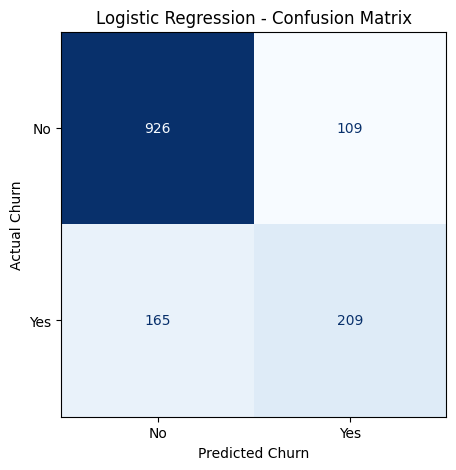

True Negatives: 926
False Positives: 109
False Negatives: 165
True Positives: 209


In [20]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Skapa Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Visualisera resultatet
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Churn")
plt.ylabel("Actual Churn")
plt.show()

# Visa antal korrekta och felaktiga förutsägelser
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


## Utvärdering av Logistic Regression – Confusion Matrix

För att utvärdera vår maskininlärningsmodell använde vi en Confusion Matrix. Den visar hur många kunder modellen klassificerade korrekt respektive felaktigt.

Modellen utvärderades på 1 409 testkunder som inte användes under träningen.

Resultatet blev följande:

- **True Negatives (TN): 926** – Kunder som stannade och klassificerades korrekt.
- **False Positives (FP): 109** – Kunder som stannade men felaktigt klassificerades som kunder som skulle lämna.
- **False Negatives (FN): 165** – Kunder som lämnade men felaktigt klassificerades som kunder som skulle stanna.
- **True Positives (TP): 209** – Kunder som lämnade och klassificerades korrekt.

Modellens utvärderingsresultat var:

- **Accuracy:** 80,55 %
- **Precision:** 65,72 %
- **Recall:** 55,88 %
- **F1-score:** 60,40 %

Modellen uppnådde högre Accuracy än vår baslinje på 73,46 %.

Samtidigt visar Confusion Matrix att modellen endast identifierade 209 av 374 kunder som faktiskt lämnade företaget.

Det innebär att modellen missade cirka 44,12 % av kundbortfallen.

Detta är en viktig begränsning eftersom ett företag som använder modellen för att identifiera kunder med risk för kundbortfall kan missa kunder som behöver uppmärksammas.

Vi bedömer därför att Logistic Regression är en användbar första modell, men att dess förmåga att identifiera kundbortfall behöver undersökas vidare.

Som nästa steg kommer vi att jämföra modellen med Random Forest för att undersöka om vi kan förbättra resultaten.

In [21]:

from sklearn.ensemble import RandomForestClassifier

# Skapa vår andra maskininlärningsmodell
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

# Träna Random Forest på träningsdatan
rf_model.fit(X_train_prepared, y_train)

# Kontrollera att modellen har tränats
print("Random Forest har tränats!")
print("Antal träningskunder:", len(y_train))
print("Antal variabler:", X_train_prepared.shape[1])
print("Antal beslutsträd:", rf_model.n_estimators)


Random Forest har tränats!
Antal träningskunder: 5634
Antal variabler: 45
Antal beslutsträd: 200


In [22]:

# Gör förutsägelser med Random Forest
rf_pred = rf_model.predict(X_test_prepared)

# Beräkna modellens resultat
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

# Skapa jämförelsetabell
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, rf_accuracy],
    "Precision": [precision, rf_precision],
    "Recall": [recall, rf_recall],
    "F1-score": [f1, rf_f1]
})

# Visa resultaten i procent
comparison.iloc[:, 1:] = comparison.iloc[:, 1:] * 100

print("Model Comparison (%)")
display(comparison.round(2))


Model Comparison (%)


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,80.55,65.72,55.88,60.40
1,Random Forest,79.99,65.75,51.34,57.66


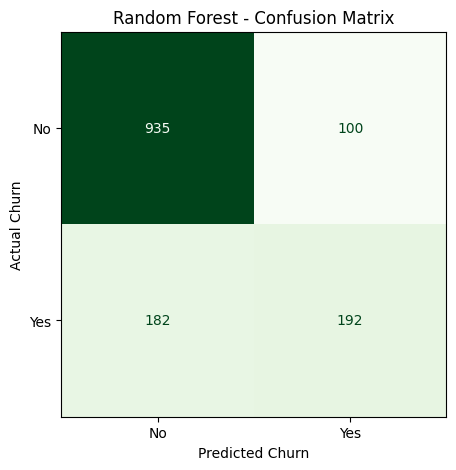

True Negatives: 935
False Positives: 100
False Negatives: 182
True Positives: 192


In [23]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Skapa Confusion Matrix för Random Forest
rf_cm = confusion_matrix(
    y_test, rf_pred, labels=[0, 1]
)

# Visualisera resultatet
rf_disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["No", "Yes"]
)

fig, ax = plt.subplots(figsize=(7, 5))

rf_disp.plot(
    ax=ax,
    cmap="Greens",
    values_format="d",
    colorbar=False
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Churn")
plt.ylabel("Actual Churn")
plt.show()

# Visa antal korrekta och felaktiga förutsägelser
rf_tn, rf_fp, rf_fn, rf_tp = rf_cm.ravel()

print("True Negatives:", rf_tn)
print("False Positives:", rf_fp)
print("False Negatives:", rf_fn)
print("True Positives:", rf_tp)


## Jämförelse av maskininlärningsmodeller (Model Comparison)

För att undersöka vilken maskininlärningsmodell som bäst kan identifiera kundbortfall jämförde vi Logistic Regression och Random Forest.

Båda modellerna tränades på samma träningsdata och utvärderades på samma 1 409 testkunder.

### Resultat

| Utvärderingsmått | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 80,55 % | 79,99 % |
| Precision | 65,72 % | 65,75 % |
| Recall | 55,88 % | 51,34 % |
| F1-score | 60,40 % | 57,66 % |

### Analys av resultaten

Logistic Regression presterade bättre än Random Forest när det gäller Accuracy, Recall och F1-score.

Random Forest hade något högre Precision, men skillnaden var endast 0,03 procentenheter.

När vi jämförde modellernas Confusion Matrix upptäckte vi att Logistic Regression missade 165 kunder som faktiskt lämnat företaget, medan Random Forest missade 182.

Det innebär att Logistic Regression identifierade 17 fler kunder som lämnat företaget.

### Val av modell

Vi föredrar Logistic Regression som vår huvudsakliga modell eftersom den uppnådde högre Recall och F1-score på testdatan.

Recall är särskilt viktigt i vårt projekt eftersom ett företag som vill minska kundbortfall behöver identifiera så många riskkunder som möjligt.

Samtidigt har modellen begränsningar. Logistic Regression missade fortfarande cirka 44,12 % av kunderna som faktiskt lämnat företaget.

Resultaten visar därför att modellen kan vara användbar för att identifiera möjliga riskkunder, men att den inte bör användas som enda beslutsunderlag.

Jämförelsen baseras på våra nuvarande modellinställningar och ett testdataset. Ytterligare validering och optimering skulle behövas innan modellen används i en verklig verksamhet.

### Slutsats

Logistic Regression gav de mest fördelaktiga resultaten av de två undersökta modellerna utifrån vårt mål att identifiera kundbortfall.

Vi väljer därför Logistic Regression som vår preliminära huvudmodell och använder Random Forest som jämförelsemodell.

In [24]:

# Hämta namnen på variablerna efter förbehandling
feature_names = preprocessor.get_feature_names_out()

# Hämta koefficienterna från Logistic Regression
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": logistic_model.coef_[0]
})

# Beräkna koefficienternas absoluta värden
coefficients["AbsoluteCoefficient"] = (
    coefficients["Coefficient"].abs()
)

# Visa de 10 största koefficienterna
top_features = coefficients.sort_values(
    by="AbsoluteCoefficient",
    ascending=False
).head(10)

print("Top 10 Logistic Regression Coefficients:")
display(top_features.round(3))


Top 10 Logistic Regression Coefficients:


,Feature,Coefficient,AbsoluteCoefficient
1,num__tenure,-1.258,1.258
38,cat__Contract_Two year,-0.777,0.777
15,cat__InternetService_DSL,-0.649,0.649
16,cat__InternetService_Fiber optic,0.634,0.634
2,num__MonthlyCharges,-0.592,0.592
36,cat__Contract_Month-to-month,0.583,0.583
3,num__TotalCharges,0.536,0.536
39,cat__PaperlessBilling_No,-0.343,0.343
25,cat__DeviceProtection_No internet service,-0.300,0.300
17,cat__InternetService_No,-0.300,0.300


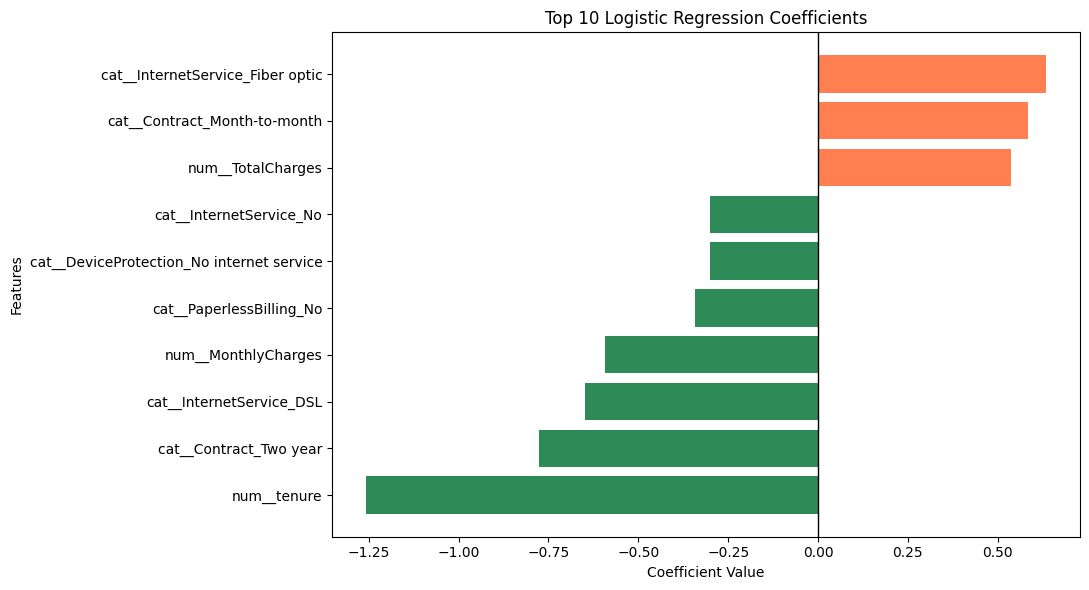

In [25]:

# Sortera de 10 största koefficienterna
plot_features = top_features.sort_values("Coefficient")

# Färger för positiva och negativa koefficienter
colors = [
    "seagreen" if coef < 0 else "coral"
    for coef in plot_features["Coefficient"]
]

# Skapa diagrammet
plt.figure(figsize=(11, 6))

plt.barh(
    plot_features["Feature"],
    plot_features["Coefficient"],
    color=colors
)

# Markera nollpunkten
plt.axvline(0, color="black", linewidth=1)

plt.title("Top 10 Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


## Tolkning av Logistic Regression – Modellens koefficienter

För att förstå hur vår Logistic Regression-modell använder olika kundegenskaper analyserade vi modellens koefficienter.

Vi identifierade de tio största koefficienterna i absoluta tal och visualiserade dem med ett horisontellt stapeldiagram.

Positiva koefficienter är förknippade med högre förutsagd sannolikhet för kundbortfall, medan negativa koefficienter är förknippade med lägre förutsagd sannolikhet, när övriga modellvariabler hålls konstanta.

### Resultat

Analysen visade bland annat följande:

- **tenure (-1,258):** Längre kundtid är förknippad med lägre förutsagd risk för kundbortfall.
- **Contract – Two year (-0,777):** Tvåårsavtal har en negativ koefficient.
- **InternetService – Fiber optic (+0,634):** Fiberuppkoppling har en positiv koefficient.
- **Contract – Month-to-month (+0,583):** Månadsavtal har en positiv koefficient.

### Tolkning och begränsningar

Resultaten överensstämmer delvis med vår tidigare explorativa dataanalys, där vi observerade högre kundbortfall bland kunder med kortare kundtid och månadsavtal.

Koefficienterna behöver dock tolkas försiktigt eftersom modellen innehåller flera relaterade variabler. Numeriska variabler har dessutom standardiserats och kategoriska variabler har omvandlats med One-Hot Encoding.

Koefficienternas absoluta storlek kan därför inte direkt användas som ett fullständigt eller jämförbart mått på variablernas betydelse.

Vi kan inte heller dra slutsatsen att de identifierade kundegenskaperna orsakar kundbortfall.

### Slutsats

Analysen hjälper oss att förstå hur vår Logistic Regression-modell använder kundernas egenskaper för att förutsäga kundbortfall.

Resultaten tyder på att kundtid och avtalstyp är relevanta variabler att undersöka närmare.

Samtidigt bör modellens koefficienter tolkas tillsammans med våra tidigare analyser och modellens utvärderingsresultat.

## Slutsats och begränsningar (Conclusion and Limitations)

### Sammanfattning av projektet

Syftet med projektet var att undersöka om maskininlärning kan användas för att identifiera kunder som riskerar att lämna ett företag.

Vi använde IBM Telco Customer Churn Dataset, som innehåller information om 7 043 kunder.

Vi genomförde datarensning, explorativ dataanalys (EDA), statistiska tester och förberedelse av data. Därefter tränade och utvärderade vi två maskininlärningsmodeller: Logistic Regression och Random Forest.

### Viktigaste resultaten

Vår analys visade att 26,54 % av kunderna i datasetet hade lämnat företaget.

Vi identifierade flera samband mellan kundernas egenskaper och kundbortfall:

- Kunder med månadsavtal hade högre andel kundbortfall än kunder med längre avtal.
- Kunder som lämnat företaget hade generellt högre månadskostnader.
- Kunder som lämnat företaget hade generellt kortare kundhistorik.

Vi genomförde även statistiska tester som gav stöd för ett samband mellan avtalstyp och kundbortfall samt en skillnad i genomsnittlig månadskostnad mellan kundgrupperna.

### Resultat från maskininlärning

Logistic Regression uppnådde följande resultat på testdatan:

- **Accuracy:** 80,55 %
- **Precision:** 65,72 %
- **Recall:** 55,88 %
- **F1-score:** 60,40 %

Random Forest uppnådde något lägre Accuracy, Recall och F1-score.

Vi valde därför Logistic Regression som vår preliminära huvudmodell.

### Begränsningar

Trots resultaten har vår analys flera begränsningar.

Logistic Regression missade 165 av de 374 kunder som faktiskt lämnade företaget i testdatan. Modellen identifierar alltså inte samtliga kunder med risk för kundbortfall.

Modellerna utvärderades med en enda uppdelning i träningsdata och testdata. Vi genomförde inte någon omfattande hyperparameteroptimering eller extern validering.

Datasetet innehåller historiska kunduppgifter, och resultaten visar statistiska samband snarare än bevisade orsakssamband.

Ytterligare validering med nyare data skulle behövas innan modellen används för verkliga affärsbeslut.

### Affärsnytta för Business Intelligence

Resultaten visar hur maskininlärning kan användas som ett komplement till traditionell Business Intelligence.

Ett företag skulle exempelvis kunna använda en vidareutvecklad modell för att identifiera kunder som kan behöva extra uppmärksamhet, analysera mönster i kundbortfall och prioritera kundlojalitetsinsatser.

Modellens förutsägelser bör dock kombineras med annan affärsinformation och mänsklig bedömning.

### Slutlig slutsats

Projektet visar att det är möjligt att använda Python, statistisk analys och maskininlärning för att undersöka och förutsäga kundbortfall i historiska kunddata.

Logistic Regression gav bäst resultat av våra två undersökta modeller utifrån projektets målsättning, men modellen behöver förbättras och valideras ytterligare innan den kan användas i en verklig verksamhet.